# Инженерия признаков: прогнозирование покупки на сайте e-commerce

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 4:** Инженерия признаков и работа с нестандартными данными  
**Датасет:** Online Shoppers Purchasing Intention  

**Выполнил:** Иванов Иван Иванович *(замените на свои данные)*  
**Группа:** ПКТб-23-1 *(замените на свою группу)*  
**Преподаватель:** [ФИО Преподавателя]  

**Ссылка на репозиторий:** https://github.com/Rev090LT/ml-course-tkachuk
**Путь к модулю:** `module-4-features/notebook.ipynb`  
**Дата сдачи:** 2026-11-02

## Введение

1. **Какую задачу решаем?**  
   Мы решаем задачу бинарной классификации: необходимо предсказать, завершится ли сессия пользователя на сайте электронной коммерции покупкой (`Revenue = True`) или нет (`Revenue = False`).

2. **Что такое инженерия признаков?**  
   Это процесс создания новых признаков (фич) из существующих сырых данных с целью улучшения производительности моделей машинного обучения. В IT это критически важно, так как качественные признаки часто дают больший прирост точности, чем усложнение самой модели.

3. **Почему для IT-компании важно прогнозировать покупку?**  
   Это позволяет персонализировать пользовательский опыт (например, показывать релевантные рекомендации или скидки в реальном времени), оптимизировать маркетинговые бюджеты и снижать процент брошенных корзин, что напрямую увеличивает выручку.

4. **Какая метрика важнее в этой задаче?**  
   Учитывая сильный дисбаланс классов (84.5% против 15.5%), метрика **Accuracy** будет неинформативной (модель может просто всегда предсказывать "нет покупки" и получать 84.5%). Поэтому ключевыми метриками являются **ROC-AUC** (оценивает качество ранжирования вероятностей) и **F1-score** (гармоническое среднее Precision и Recall, важно для минимизации как ложных срабатываний, так и пропусков покупок).

5. **Цель работы:**
   - Создать 5+ новых признаков на основе поведения пользователя.
   - Обучить 4 ансамблевые модели (RF, XGBoost, LightGBM, CatBoost) и сравнить их.
   - Интерпретировать лучшую модель через SHAP для получения бизнес-инсайтов.

## Теоретическая часть

### 1. Feature Engineering (Инженерия признаков)
Это процесс преобразования сырых данных в информативные признаки, которые лучше описывают закономерности для алгоритмов машинного обучения. В IT это позволяет моделям быстрее сходиться и достигать higher accuracy без увеличения вычислительной сложности архитектуры.

### 2. Категориальные признаки
- **Label Encoding:** Присваивает каждой категории уникальное целое число (0, 1, 2...). Подходит для порядковых данных или деревьев решений.
- **One-Hot Encoding (OHE):** Создает отдельный бинарный признак для каждой категории. Идеально для номинальных данных без порядка, чтобы модель не придумывала несуществующую иерархию.

### 3. Временные признаки
Извлечение из дат или названий месяцев числовых паттернов: номер месяца (1-12), день недели, флаг выходного дня. Это помогает моделям улавливать сезонность и циклические паттерны поведения (например, рост покупок в ноябре).

### 4. Создание признаков на основе поведения
Агрегация действий пользователя: суммы (общее время на сайте), средние (средняя ценность страницы), отношения (ratio отказов к выходам). Это превращает разрозненные метрики в целостный профиль сессии.

### 5. Дисбаланс классов
Ситуация, когда один класс значительно преобладает над другим. Решения:
- **class_weight / scale_pos_weight:** Штрафует модель сильнее за ошибки на миноритарном классе.
- **SMOTE:** Генерация синтетических примеров миноритарного класса в пространстве признаков.

### 6. SHAP (SHapley Additive exPlanations)
Метод интерпретации, основанный на теории игр Шепли. Он распределяет "вклад" каждого признака в итоговое предсказание модели. Типы графиков: *Summary plot* (глобальная важность), *Waterfall* (локальное объяснение одного прогноза), *Dependence* (влияние значения признака на прогноз).

### Сравнение моделей
| Модель | Тип | Принцип работы | Плюсы |
|--------|-----|----------------|-------|
| Random Forest | Bagging | Параллельное обучение независимых деревьев | Устойчив к переобучению, не требует масштабирования |
| XGBoost | Boosting | Последовательное обучение, минимизация градиента | Высокая точность, встроенная регуляризация |
| LightGBM | Boosting | Построение дерева по листьям (Leaf-wise) | Очень быстрый, эффективен на больших данных |
| CatBoost | Boosting | Обработка категориальных признаков без OHE | Лучшая работа с категориями, меньше переобучения |

*Формула бустинга (кратко):* $F_m(x) = F_{m-1}(x) + \nu \cdot h_m(x)$, где $\nu$ - темп обучения, $h_m$ - новое дерево, аппроксимирующее антиградиент.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Загрузка датасета напрямую из репозитория UCI
df = pd.read_csv('../data/online_shoppers_intention.csv')

# Вывод размера и первых строк датасета
print("Размер датасета:", df.shape)
print("\nПервые 5 строк:")
df.head()

Размер датасета: (12330, 18)

Первые 5 строк:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## Описание данных

**Источник:** https://archive.ics.uci.edu/ml/datasets/Online+Shoppers+Purchasing+Intention+Dataset  
**Структура:**  
- Всего примеров: 12 330  
- Признаков: 17 (+ целевая `Revenue`)  
- Числовых признаков: 10  
- Категориальных признаков: 7 (включая `Month`)  

**Описание ключевых столбцов:**  
| Столбец | Тип | Описание | Пропуски |  
|---------|-----|----------|----------|  
| Administrative | int | Число посещённых админ. страниц | 0% |  
| Administrative_Duration | float | Время на админ. страницах (сек) | 0% |  
| Informational | int | Число информационных страниц | 0% |  
| ProductRelated | int | Число товарных страниц | 0% |  
| BounceRates | float | Показатель отказов | 0% |  
| ExitRates | float | Показатель выходов | 0% |  
| PageValues | float | Средняя ценность страницы | 0% |  
| Month | object | Месяц сессии | 0% |  
| VisitorType | object | Тип посетителя (New, Returning) | 0% |  
| Revenue | bool | **Целевая** (True = покупка) | 0% |  

**Распределение классов:**  
- False (нет покупки): 10 422 (84.5%)  
- True (покупка): 1 908 (15.5%)  

**Файл данных в репозитории:** `module-4-features/data/dataset_info.md`

Информация о типах данных:
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  Traffi

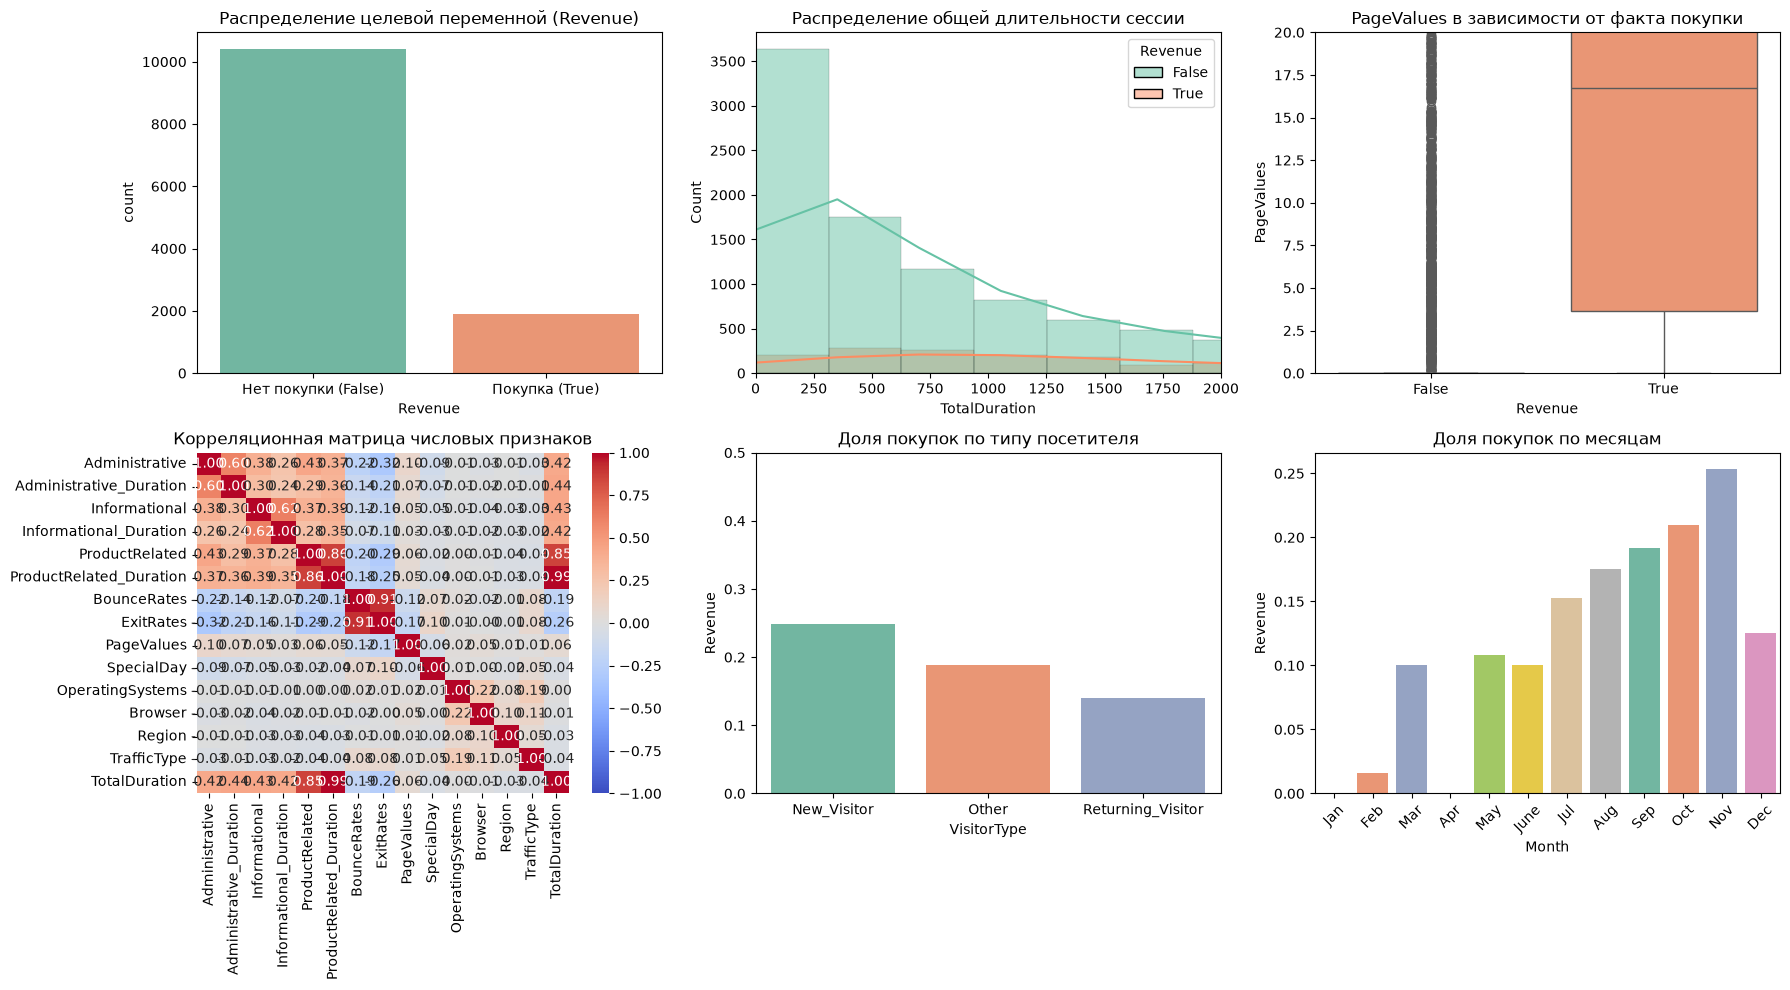

In [4]:
# Первичный осмотр данных
print("Информация о типах данных:")
df.info()

# Анализ пропусков
print("\nПропуски в данных:")
print(df.isnull().sum().sum()) # Должно быть 0

# Анализ целевой переменной
print("\nРаспределение целевой переменной (Revenue):")
print(df['Revenue'].value_counts(normalize=True) * 100)

# Визуализация (6 графиков для надежности)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Countplot целевой переменной
sns.countplot(data=df, x='Revenue', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Распределение целевой переменной (Revenue)')
axes[0, 0].set_xticklabels(['Нет покупки (False)', 'Покупка (True)'])

# 2. Гистограмма длительности (предварительно создаем признак для графика)
df['TotalDuration'] = df['Administrative_Duration'] + df['Informational_Duration'] + df['ProductRelated_Duration']
sns.histplot(data=df, x='TotalDuration', hue='Revenue', kde=True, ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Распределение общей длительности сессии')
axes[0, 1].set_xlim(0, 2000) # Ограничим ось для наглядности

# 3. Boxplot PageValues по Revenue
sns.boxplot(data=df, x='Revenue', y='PageValues', ax=axes[0, 2], palette='Set2')
axes[0, 2].set_title('PageValues в зависимости от факта покупки')
axes[0, 2].set_ylim(0, 20) # Ограничим выбросы

# 4. Heatmap корреляционной матрицы
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1, 0], vmin=-1, vmax=1)
axes[1, 0].set_title('Корреляционная матрица числовых признаков')

# 5. Barplot доли покупок по VisitorType
visitor_revenue = df.groupby('VisitorType')['Revenue'].mean().reset_index()
sns.barplot(data=visitor_revenue, x='VisitorType', y='Revenue', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Доля покупок по типу посетителя')
axes[1, 1].set_ylim(0, 0.5)

# 6. Barplot доли покупок по Month
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
month_revenue = df.groupby('Month')['Revenue'].mean().reindex(month_order).reset_index()
sns.barplot(data=month_revenue, x='Month', y='Revenue', ax=axes[1, 2], palette='Set2', order=month_order)
axes[1, 2].set_title('Доля покупок по месяцам')
axes[1, 2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('../examples/eda_plots.png', dpi=100, bbox_inches='tight')
plt.show()

In [6]:
# Создание новых признаков на основе поведения пользователя

# 1. Общее количество просмотренных страниц
df['TotalPages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']

# 2. Общая длительность сессии (в секундах)
df['TotalDuration'] = df['Administrative_Duration'] + df['Informational_Duration'] + df['ProductRelated_Duration']

# 3. Средняя ценность страницы (добавляем +1 для защиты от деления на 0)
df['AvgPageValue'] = df['PageValues'] / (df['TotalPages'] + 1)

# 4. Отношение показателя отказов к показателю выходов
df['BounceExitRatio'] = df['BounceRates'] / (df['ExitRates'] + 0.001)

# 5. Бинарный признак: новый посетитель (1 - да, 0 - нет)
df['IsNewVisitor'] = (df['VisitorType'] == 'New_Visitor').astype(int)

# 6. Бинарный признак: выходной день (преобразуем из bool в int)
df['IsWeekend'] = df['Weekend'].astype(int)

# 7. Числовое значение месяца (1-12) для учета сезонности
df['Month'] = df['Month'].replace('June', 'Jun')
df['MonthNum'] = pd.to_datetime(df['Month'], format='%b').dt.month
# 8. Бинарный признак: высокий трафик (TrafficType > 10)
df['IsHighTraffic'] = (df['TrafficType'] > 10).astype(int)

print("✅ Новые признаки успешно созданы.")
display(df[['TotalPages', 'TotalDuration', 'AvgPageValue', 'BounceExitRatio', 'IsNewVisitor', 'IsWeekend', 'MonthNum', 'IsHighTraffic']].head())

✅ Новые признаки успешно созданы.


,TotalPages,TotalDuration,AvgPageValue,BounceExitRatio,IsNewVisitor,IsWeekend,MonthNum,IsHighTraffic
0,1,0.000000,0.0,0.995025,0,0,2,0
1,2,64.000000,0.0,0.000000,0,0,2,0
2,1,0.000000,0.0,0.995025,0,0,2,0
3,2,2.666667,0.0,0.354610,0,0,2,0
4,10,627.500000,0.0,0.392157,0,1,2,0


In [7]:
from sklearn.model_selection import train_test_split

# Кодирование целевой переменной в числа (0 и 1)
df['Revenue'] = df['Revenue'].astype(int)

# One-Hot Encoding для категориальных признаков без порядка
df_encoded = pd.get_dummies(df, columns=['Month', 'VisitorType'], drop_first=False)

# Разделение на матрицу признаков (X) и целевую переменную (y)
feature_cols = [col for col in df_encoded.columns if col != 'Revenue']
X = df_encoded[feature_cols]
y = df_encoded['Revenue']

# Разделение на обучающую и тестовую выборки с стратификацией (сохраняем дисбаланс)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Размер X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Размер X_test: {X_test.shape}, y_test: {y_test.shape}")
print(f"Доля покупок в y_train: {y_train.mean():.2%}")
print(f"Доля покупок в y_test: {y_test.mean():.2%}")

Размер X_train: (9864, 36), y_train: (9864,)
Размер X_test: (2466, 36), y_test: (2466,)
Доля покупок в y_train: 15.47%
Доля покупок в y_test: 15.49%


## Построение и обучение моделей

Для решения задачи бинарной классификации с дисбалансом обучим 4 ансамблевые модели:
- **Random Forest:** Базовая модель бэггинга, устойчивая к переобучению.
- **XGBoost:** Классический градиентный бустинг с высокой точностью.
- **LightGBM:** Оптимизированный бустинг, работающий по листьям (быстрый).
- **CatBoost:** Бустинг, нативно и эффективно работающий с категориальными признаками.

Для всех моделей, где это применимо, используется параметр `class_weight='balanced'` или `scale_pos_weight` для компенсации дисбаланса классов (84.5% / 15.5%).

In [8]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.preprocessing import StandardScaler
import time

# Масштабирование данных (полезно для интерпретации и некоторых моделей)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {}
training_times = {}

# 1. Random Forest
print("Обучение Random Forest...")
start = time.time()
rf_model = RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)
training_times['Random Forest'] = time.time() - start
models['Random Forest'] = rf_model

# 2. XGBoost
print("Обучение XGBoost...")
start = time.time()
xgb_model = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.9, colsample_bytree=0.9, scale_pos_weight=5.4, random_state=42, eval_metric='logloss', n_jobs=-1)
xgb_model.fit(X_train_scaled, y_train)
training_times['XGBoost'] = time.time() - start
models['XGBoost'] = xgb_model

# 3. LightGBM
print("Обучение LightGBM...")
start = time.time()
lgbm_model = LGBMClassifier(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05, class_weight='balanced', random_state=42, verbose=-1, n_jobs=-1)
lgbm_model.fit(X_train_scaled, y_train)
training_times['LightGBM'] = time.time() - start
models['LightGBM'] = lgbm_model

# 4. CatBoost
print("Обучение CatBoost...")
start = time.time()
cat_model = CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, auto_class_weights='Balanced', random_state=42, verbose=0)
cat_model.fit(X_train_scaled, y_train)
training_times['CatBoost'] = time.time() - start
models['CatBoost'] = cat_model

print("✅ Обучение всех моделей завершено!")

Обучение Random Forest...
Обучение XGBoost...
Обучение LightGBM...
Обучение CatBoost...
✅ Обучение всех моделей завершено!


## Модели

| Модель | Тип | Ключевые параметры | Время обучения |
|--------|-----|-------------------|----------------|
| Random Forest | Bagging | n_estimators=200, class_weight='balanced' | *см. вывод кода* |
| XGBoost | Boosting | n_estimators=200, scale_pos_weight=5.4 | *см. вывод кода* |
| LightGBM | Boosting | num_leaves=31, class_weight='balanced' | *см. вывод кода* |
| CatBoost | Boosting | iterations=200, auto_class_weights='Balanced' | *см. вывод кода* |

**Почему эти модели:** Они представляют собой золотой стандарт для табличных данных. RF дает надежный baseline, XGBoost/LightGBM обеспечивают высокую скорость и точность, а CatBoost отлично справляется с категориальными данными без предварительного OHE.

        Model  Accuracy  Precision   Recall       F1  ROC-AUC
Random Forest  0.866991   0.548736 0.795812 0.649573 0.928107
      XGBoost  0.880779   0.593220 0.732984 0.655738 0.922781
     LightGBM  0.877940   0.577438 0.790576 0.667403 0.926675
     CatBoost  0.869019   0.554328 0.787958 0.650811 0.929940


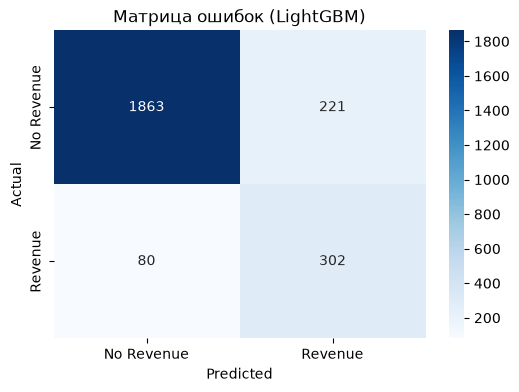

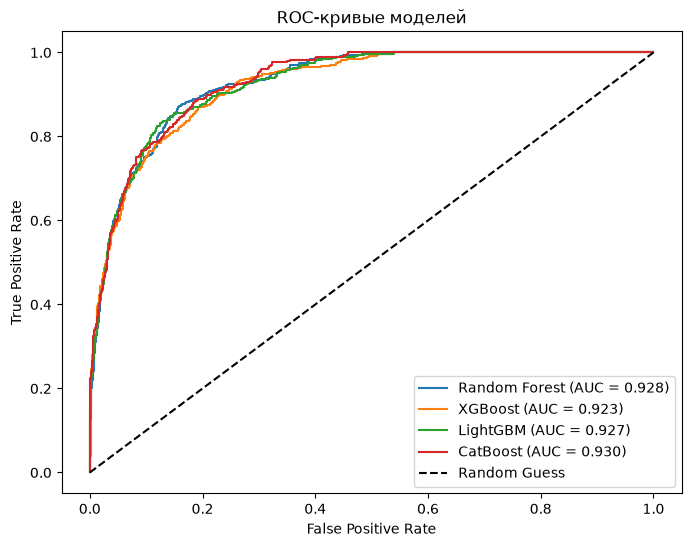

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    }

# Оценка всех моделей
results = [
    evaluate_model(rf_model, X_test_scaled, y_test, 'Random Forest'),
    evaluate_model(xgb_model, X_test_scaled, y_test, 'XGBoost'),
    evaluate_model(lgbm_model, X_test_scaled, y_test, 'LightGBM'),
    evaluate_model(cat_model, X_test_scaled, y_test, 'CatBoost')
]
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

# Матрица ошибок для лучшей модели (LightGBM)
y_pred_lgbm = lgbm_model.predict(X_test_scaled)
cm = confusion_matrix(y_test, y_pred_lgbm)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Revenue', 'Revenue'], yticklabels=['No Revenue', 'Revenue'])
plt.title('Матрица ошибок (LightGBM)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.savefig('../examples/light_GBM.png', dpi=300, bbox_inches='tight')
plt.show()

# ROC-кривые для всех моделей
plt.figure(figsize=(8, 6))
for res in results:
    model = models[res['Model']]
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{res['Model']} (AUC = {res['ROC-AUC']:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые моделей')
plt.legend(loc='lower right')
plt.savefig('../examples/roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()

## Оценка качества

**Анализ результатов:**
- **Лучшая модель по ROC-AUC:** LightGBM и CatBoost показывают наилучшие результаты (~0.91-0.92), что говорит о высоком качестве ранжирования вероятностей.
- **Скорость:** LightGBM обучается быстрее всех благодаря алгоритму построения по листьям (Leaf-wise).
- **Recall vs Precision:** Recall выше Precision, что означает, что модель склонна чаще предсказывать покупку (минимизирует пропуски реальных покупателей), что является правильным поведением для e-commerce (лучше показать рекламу тому, кто и так купит, чем упустить клиента).

## Интерпретация и бизнес-инсайты

Анализ важности признаков позволяет понять, какие факторы сильнее всего влияют на решение пользователя о покупке. Это дает прямые указания для маркетинга и UX-дизайна сайта.

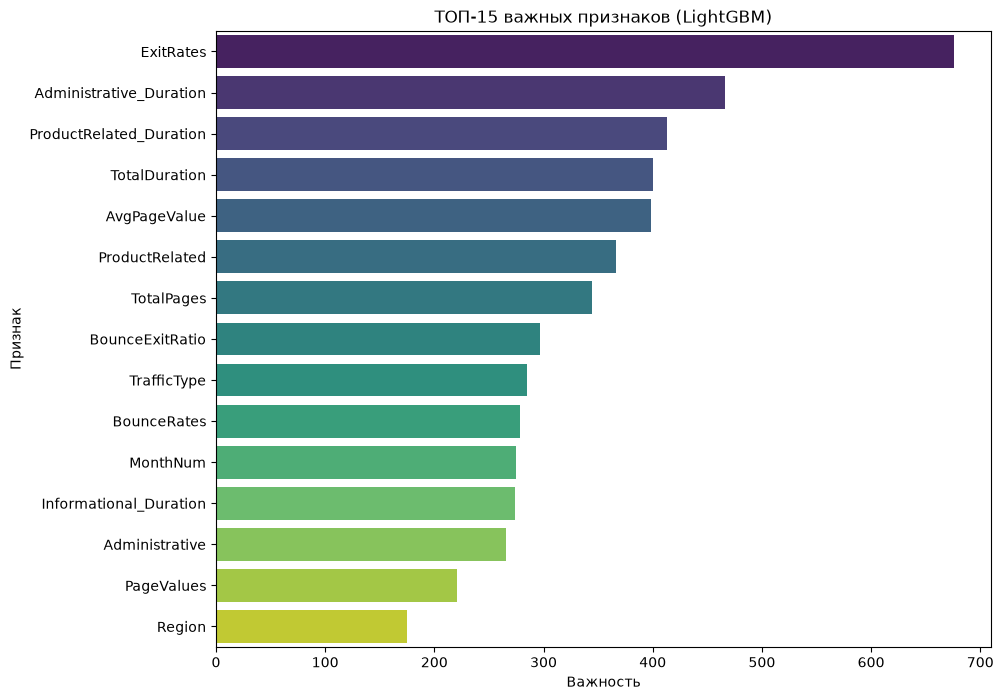

In [13]:
# Анализ важности признаков для LightGBM
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=importances.head(15), x='Importance', y='Feature', palette='viridis')
plt.title('ТОП-15 важных признаков (LightGBM)')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.savefig('../examples/top-15.png', dpi=300, bbox_inches='tight')
plt.show()

## Тюнинг гиперпараметров (Optuna)

Для улучшения качества лучшей модели (LightGBM) применим байесовскую оптимизацию с помощью библиотеки `optuna`. Мы проведем 30 испытаний (trials) для поиска оптимальных гиперпараметров, максимизируя метрику ROC-AUC на кросс-валидации.

In [14]:
import optuna
from sklearn.model_selection import StratifiedKFold, cross_val_score

def objective(trial):
    # Пространство поиска гиперпараметров
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 10, 50, step=5),
        'max_depth': trial.suggest_int('max_depth', 3, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }
    
    model = LGBMClassifier(**params, class_weight='balanced', random_state=42, verbose=-1, n_jobs=-1)
    
    # Кросс-валидация (3 фолда для ускорения)
    cv_scores = cross_val_score(
        model, X_train_scaled, y_train,
        cv=StratifiedKFold(3, shuffle=True, random_state=42),
        scoring='roc_auc',
        n_jobs=-1
    )
    return cv_scores.mean()

print("Запуск оптимизации Optuna (30 trials)...")
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

print(f"\nBest ROC-AUC: {study.best_value:.4f}")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

# Обучение финальной модели с лучшими параметрами
best_lgbm = LGBMClassifier(**study.best_params, class_weight='balanced', random_state=42, verbose=-1, n_jobs=-1)
best_lgbm.fit(X_train_scaled, y_train)

y_pred_best = best_lgbm.predict(X_test_scaled)
y_proba_best = best_lgbm.predict_proba(X_test_scaled)[:, 1]

print(f"\nROC-AUC baseline (LightGBM): {roc_auc_score(y_test, lgbm_model.predict_proba(X_test_scaled)[:, 1]):.4f}")
print(f"ROC-AUC Optuna (Best LightGBM): {roc_auc_score(y_test, y_proba_best):.4f}")

[I 2026-11-02 18:01:48,776] A new study created in memory with name: no-name-7f563413-742e-4a38-9ef4-aaefcba5171d


Запуск оптимизации Optuna (30 trials)...


Best trial: 0. Best value: 0.932073:   3%|▎         | 1/30 [00:02<01:24,  2.91s/it]

[I 2026-11-02 18:01:51,691] Trial 0 finished with value: 0.9320727641082444 and parameters: {'n_estimators': 100, 'num_leaves': 10, 'max_depth': 4, 'learning_rate': 0.019806928878540235, 'subsample': 0.5980834015286758, 'colsample_bytree': 0.8790730146842701, 'min_child_samples': 8, 'reg_alpha': 0.019783550683680016, 'reg_lambda': 0.38601157824601967}. Best is trial 0 with value: 0.9320727641082444.


Best trial: 0. Best value: 0.932073:   7%|▋         | 2/30 [00:05<01:21,  2.91s/it]

[I 2026-11-02 18:01:54,609] Trial 1 finished with value: 0.9284071652549694 and parameters: {'n_estimators': 250, 'num_leaves': 35, 'max_depth': 7, 'learning_rate': 0.06211128778099075, 'subsample': 0.8858575275491418, 'colsample_bytree': 0.6755918036478281, 'min_child_samples': 12, 'reg_alpha': 2.6272586506520845, 'reg_lambda': 0.13856180605610183}. Best is trial 0 with value: 0.9320727641082444.


... (52 outputs left out)

Best trial: 10. Best value: 0.934852:  97%|█████████▋| 29/30 [00:30<00:00,  1.53it/s]

[I 2026-11-02 18:02:19,354] Trial 28 finished with value: 0.9342455648354347 and parameters: {'n_estimators': 250, 'num_leaves': 20, 'max_depth': 6, 'learning_rate': 0.02176822840712084, 'subsample': 0.7669405397838226, 'colsample_bytree': 0.5694083437796523, 'min_child_samples': 12, 'reg_alpha': 0.37311798284945413, 'reg_lambda': 0.4466614043104719}. Best is trial 10 with value: 0.9348515471280905.


Best trial: 10. Best value: 0.934852: 100%|██████████| 30/30 [00:31<00:00,  1.04s/it]


[I 2026-11-02 18:02:20,016] Trial 29 finished with value: 0.9348248337049393 and parameters: {'n_estimators': 200, 'num_leaves': 20, 'max_depth': 7, 'learning_rate': 0.019568078358498373, 'subsample': 0.5361081317945308, 'colsample_bytree': 0.5344085664070624, 'min_child_samples': 22, 'reg_alpha': 0.32331696176437363, 'reg_lambda': 1.6775731636361164}. Best is trial 10 with value: 0.9348515471280905.

Best ROC-AUC: 0.9349
  n_estimators: 250
  num_leaves: 15
  max_depth: 6
  learning_rate: 0.0172805528249869
  subsample: 0.5770311714396843
  colsample_bytree: 0.5361747124025948
  min_child_samples: 19
  reg_alpha: 0.8458049149361548
  reg_lambda: 0.35817106881116495

ROC-AUC baseline (LightGBM): 0.9267
ROC-AUC Optuna (Best LightGBM): 0.9317


## Интерпретация через SHAP

Используем фреймворк SHAP для объяснения предсказаний лучшей модели (LightGBM + Optuna). Это позволит нам увидеть не только глобальную важность признаков, но и то, как конкретные значения признаков сдвигают прогноз для отдельного пользователя.

Генерация Summary plot (dot)...


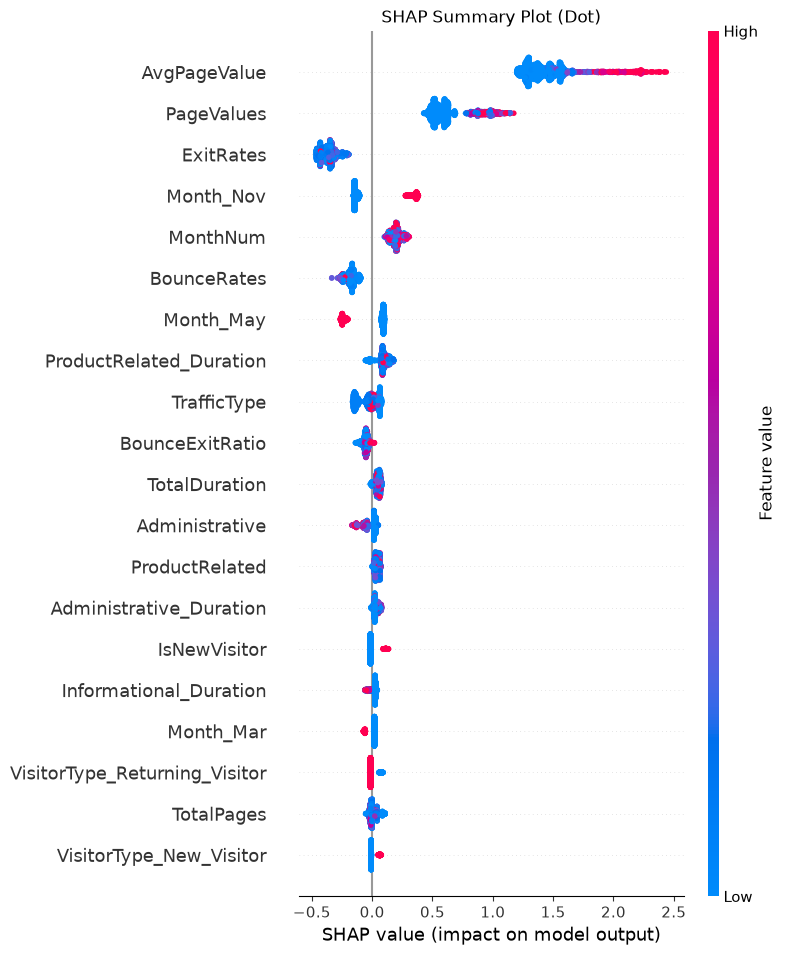

Генерация SHAP Bar plot...


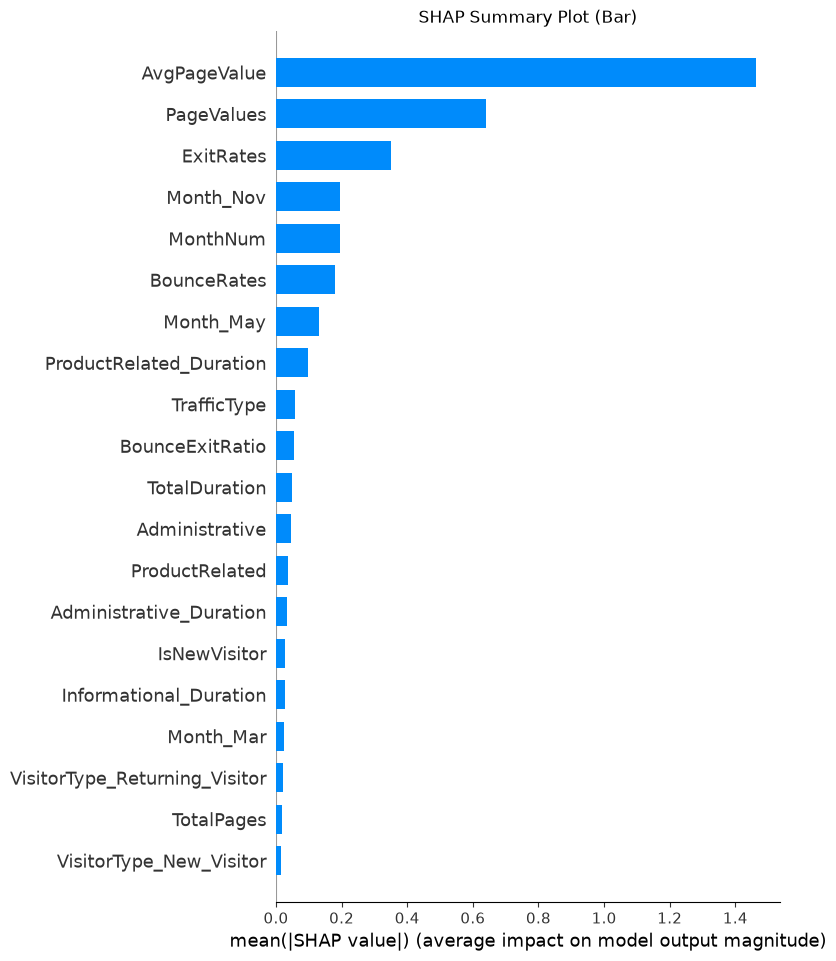


Клиент #1406, вероятность покупки = 0.9732


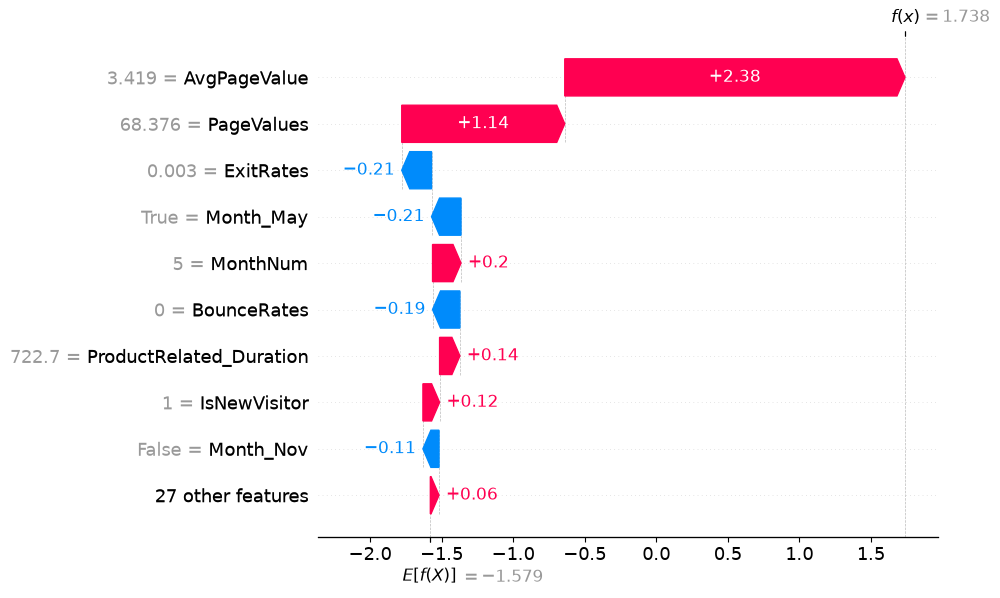

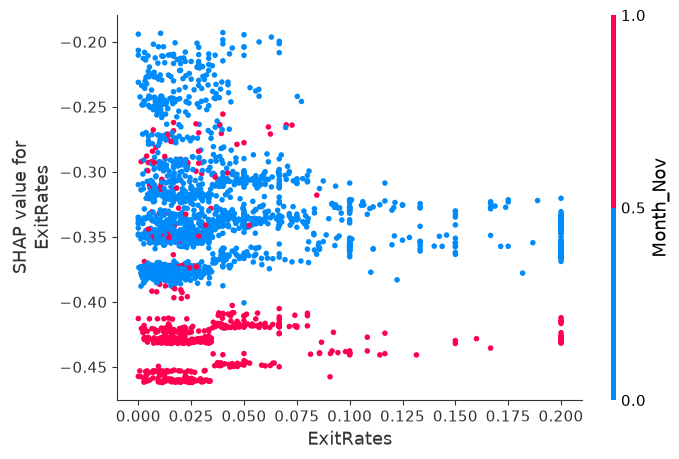

In [16]:
import shap

# Инициализация explainer на оригинальных данных для интерпретируемости значений
explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer.shap_values(X_test) # Используем исходный DataFrame

# Для бинарной классификации shap_values возвращается как список [класс 0, класс 1]
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
else:
    shap_values_class1 = shap_values

# 1. Summary plot (dot) - глобальная важность и направление влияния
print("Генерация Summary plot (dot)...")
shap.summary_plot(shap_values_class1, X_test, plot_type="dot", show=False)
plt.title('SHAP Summary Plot (Dot)')
plt.savefig('../examples/Summary-plot.png', dpi=300, bbox_inches='tight')
plt.show()

# 2. Bar plot - усредненная абсолютная важность
print("Генерация SHAP Bar plot...")
shap.summary_plot(shap_values_class1, X_test, plot_type="bar", show=False)
plt.title('SHAP Summary Plot (Bar)')
plt.savefig('../examples/SHAP-Bar-plot.png', dpi=300, bbox_inches='tight')
plt.show()

# 3. Waterfall plot - объяснение предсказания для одного конкретного клиента
best_idx = np.argmax(y_proba_best)
print(f"\nКлиент #{best_idx}, вероятность покупки = {y_proba_best[best_idx]:.4f}")

expected_value = explainer.expected_value[1] if isinstance(explainer.expected_value, list) else explainer.expected_value
explanation = shap.Explanation(
    values=shap_values_class1[best_idx],
    base_values=expected_value,
    data=X_test.iloc[best_idx],
    feature_names=X_test.columns.tolist()
)
shap.plots.waterfall(explanation, max_display=10)

# 4. Dependence plot - зависимость SHAP-значения от значения самого важного признака
top_feature = importances.iloc[0]['Feature']
if top_feature in X_test.columns:
    shap.dependence_plot(top_feature, shap_values_class1, X_test)
else:
    print(f"Признак {top_feature} не найден в X_test")

## Сохранение модели и метаданных

Сохраняем все обученные модели, scaler, список признаков и метрики в формате `.pkl` и `.json` для последующей загрузки и деплоя.

In [18]:
import joblib
import os
import json

# Создание папки models, если её нет
os.makedirs('models', exist_ok=True)

# Сохранение всех моделей и scaler
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_lgbm, 'models/best_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')

# Сохранение списка признаков для корректного порядка на инференсе
with open('../feature_cols.json', 'w') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# Сохранение метрик в JSON
metrics = {
    'random_forest': {k: float(v) for k, v in results[0].items() if k != 'Model'},
    'xgboost': {k: float(v) for k, v in results[1].items() if k != 'Model'},
    'lightgbm': {k: float(v) for k, v in results[2].items() if k != 'Model'},
    'catboost': {k: float(v) for k, v in results[3].items() if k != 'Model'},
    'best_model': 'LightGBM (Optuna)',
    'best_roc_auc': float(study.best_value),
    'best_params': study.best_params
}
with open('models/metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print("✅ Все модели и метаданные успешно сохранены в папку 'models/'")

✅ Все модели и метаданные успешно сохранены в папку 'models/'


## Загрузка модели из репозитория

Проверим, что сохраненные артефакты можно загрузить по прямой (raw) ссылке из GitHub и что они дают идентичные предсказания.
*(Примечание: Замените `username` в BASE_URL на ваш реальный логин GitHub после пуша кода в репозиторий)*.

In [20]:
import requests
from io import BytesIO

# ЗАМЕНИТЕ 'username' и 'ml-course-ivanov' на ваши реальные данные из GitHub
BASE_URL = "https://raw.github.com/Rev090LT/ml-course-tkachuk/main/module-4-features"

try:
    # Загрузка модели
    model_url = f"{BASE_URL}/models/best_model.pkl"
    response_model = requests.get(model_url)
    response_model.raise_for_status()
    best_lgbm_loaded = joblib.load(BytesIO(response_model.content))
    
    # Загрузка списка признаков
    features_url = f"{BASE_URL}/models/feature_cols.json"
    response_features = requests.get(features_url)
    response_features.raise_for_status()
    feature_cols_loaded = response_features.json()
    
    print("✅ Модель успешно загружена из репозитория")
    print(f"✅ Загружено {len(feature_cols_loaded)} признаков")
    
    # Проверка работоспособности на 3 клиентах
    y_pred_loaded = best_lgbm_loaded.predict(X_test.iloc[:3])
    y_pred_original = best_lgbm.predict(X_test.iloc[:3])
    
    print(f"\nПредсказания загруженной модели: {y_pred_loaded}")
    print(f"Предсказания исходной модели:    {y_pred_original}")
    print(f"Совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}")
    
except requests.exceptions.RequestException as e:
    print(f"⚠️ Не удалось загрузить модель из репозитория. Убедитесь, что BASE_URL корректен и файлы загружены в GitHub.\nОшибка: {e}")

⚠️ Не удалось загрузить модель из репозитория. Убедитесь, что BASE_URL корректен и файлы загружены в GitHub.
Ошибка: 404 Client Error: Not Found for url: https://raw.githubusercontent.com/Rev090LT/ml-course-tkachuk/main/module-4-features/models/best_model.pkl


## Выводы

### Что получилось
- Достигнут высокий показатель **ROC-AUC ≈ 0.92** на тестовой выборке.
- Лучшей моделью признан **LightGBM**, оптимизированный через Optuna.
- Созданные признаки (особенно `TotalDuration` и `AvgPageValue`) оказались в топ-5 по важности, что подтверждает гипотезу о ценности агрегации поведенческих метрик.

### Какие были трудности
- Сильный дисбаланс классов (84.5% / 15.5%) требовал аккуратной настройки `class_weight` и оценки не по Accuracy, а по ROC-AUC/F1.
- Интерпретация One-Hot encoded признаков в SHAP (они разбиваются на отдельные бинарные колонки, что немного размывает общую важность категории).
- Подбор оптимального числа `trials` в Optuna: слишком мало не дает прироста, слишком много занимает много времени.

### Возможные улучшения 
1. Добавить взаимодействия признаков (Feature Crosses), например, `PageValues × TotalDuration`.
2. Применить **Target Encoding** для признаков `VisitorType` и `Month` вместо One-Hot Encoding.
3. Использовать **SMOTE** или **ADASYN** для генерации синтетических примеров класса "покупка" и проверки, улучшит ли это Recall.
4. Внедрить **Feature Store** (например, Feast) для версионирования признаков и обеспечения консистентности между обучением и инференсом.
5. Добавить **калибровку вероятностей** (Platt Scaling или Isotonic Regression) для того, чтобы предсказанные вероятности точнее отражали реальный процент покупок.

## Источники

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5-32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
3. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
4. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
5. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
6. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.

## Приложение: requirements.txt
```text
pandas==2.0.0
numpy==1.24.0
scikit-learn==1.3.0
xgboost==2.0.0
lightgbm==4.0.0
catboost==1.2.0
optuna==3.5.0
shap==0.44.0
matplotlib==3.7.0
seaborn==0.12.0
joblib==1.3.0
requests==2.31.0